# U03.E05 · Motor recomendador reproducible
**INF-8239 Ciencia de Datos II** · Unidad 03 · Algoritmos y características generativas
Estudiante: _[Nombre y matrícula]_ · Docente: Edwin Ramón José Nolasco

Este notebook reúne las evidencias de **LAB08** (MovieLens, popularidad, contenido) y **LAB09** (factorización, ranking offline, híbrido, cold start, costo).
Ejecuta el protocolo completo de `src/inf8239_u03/pipeline.py`, que escribe todas las tablas y figuras en `reports/`.

> **Datos:** MovieLens Latest Small (GroupLens). **No se redistribuye.** Obténgalo con `python scripts/download_data.py` (ver README).

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from inf8239_u03 import config
from inf8239_u03.data import load_movielens, audit
from inf8239_u03.pipeline import run_all

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
REP = config.REPORTS; FIG = REP / "figures"
print("raíz del proyecto:", ROOT)

raíz del proyecto: /home/claude/e05


## 1. Datos, licencia y auditoría

In [2]:
man = json.loads(config.MANIFEST.read_text())
print("Fuente oficial:", man["official_url"])
print("Términos de uso:", man["license_readme"])
print("SHA-256 del zip:", man["sha256_zip"], f"({man['bytes']:,} bytes)")
print("Obtenido (UTC):", man["retrieved_utc"])
ml = load_movielens()
pd.Series(audit(ml), name="valor").to_frame()

Fuente oficial: https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
Términos de uso: https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html
SHA-256 del zip: 696d65a3dfceac7c45750ad32df2c259311949efec81f0f144fdfb91ebc9e436 (978,202 bytes)
Obtenido (UTC): 2026-11-08T15:18:54+00:00


,valor
usuarios,610
peliculas_catalogo,9742
peliculas_valoradas,9724
valoraciones,100836
densidad,0.017
rating_medio,3.5016
min_valoraciones_por_usuario,20
mediana_valoraciones_por_usuario,70.5
peliculas_con_1_valoracion,3446
pct_valoraciones_top10pct_items,0.6002


**Lectura.** 610 usuarios, 9 742 películas y 100 836 valoraciones: la matriz está llena en un 1,7 %. Que falte una valoración **no** significa rechazo, sino que esa combinación no se observó. El 10 % de películas más valoradas concentra el 60 % de las valoraciones (cola larga), y 3 446 películas tienen una sola valoración. Todas las personas tienen ≥ 20 valoraciones por diseño del dataset, así que no hay usuarios nuevos reales y el arranque en frío se simula (sección 7). Tampoco hay demografía.

## 2. Ejecución del protocolo completo
Una sola llamada reproduce todo: LAB08, corte temporal, selección en validación (3 semillas), prueba única, usuarios fríos, perfiles y figuras (~10 min en CPU).

In [3]:
t0 = time.time()
res = run_all(ml, out=REP)
print(f"tiempo total: {time.time()-t0:.0f} s")

[1/6] LAB08: auditoría, popularidad y contenido
[2/6] Corte temporal leave-last-out
[3/6] Selección en validación (3 semillas)


  MF f= 10 ep= 12 seed=42    RMSE_val=0.8963  8.7s


  MF f= 10 ep= 12 seed=7     RMSE_val=0.8933  9.2s


  MF f= 10 ep= 12 seed=2025  RMSE_val=0.8889  9.7s


  MF f= 10 ep= 25 seed=42    RMSE_val=0.8951  18.9s


  MF f= 10 ep= 25 seed=7     RMSE_val=0.8905  17.8s


... (19 outputs left out)

  frío seed=42: 61 usuarios fríos


  frío seed=7: 61 usuarios fríos


  frío seed=2025: 61 usuarios fríos
[6/6] Perfiles, figuras y resumen


Listo en 655.4 s → /home/claude/e05/reports
tiempo total: 655 s


## 3. LAB08 · Popularidad suavizada y contenido
### 3.1 Top-10 de popularidad suavizada
`weighted_score = n/(n+m)·media + m/(n+m)·media_global`, con *m* = percentil 90 del número de valoraciones por película.

In [4]:
print("m =", res["lab08"]["pop_m"])
display(res["lab08"]["popularity_top10"])
print("Comparación: Top-10 por media CRUDA (sin suavizar)")
display(res["lab08"]["popularity_raw"])

m = 27.0


,movieId,title,genres,mean,count,weighted_score
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.4290,317,4.3562
1,858,"Godfather, The (1972)",Crime|Drama,4.2891,192,4.1920
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.2729,218,4.1879
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.2311,251,4.1602
4,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.2377,204,4.1517
5,527,Schindler's List (1993),Drama|War,4.2250,220,4.1459
6,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.1971,307,4.1408
7,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,4.2156,211,4.1346
8,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.1924,278,4.1313
9,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.2597,129,4.1285


Comparación: Top-10 por media CRUDA (sin suavizar)


,title,mean,count,weighted_score
871,Lamerica (1994),5.0,2,3.6049
872,Heidi Fleiss: Hollywood Madam (1995),5.0,2,3.6049
873,Lesson Faust (1994),5.0,2,3.6049
874,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,5.0,2,3.6049
875,Belle époque (1992),5.0,2,3.6049
876,Come and See (Idi i smotri) (1985),5.0,2,3.6049
877,Enter the Void (2009),5.0,2,3.6049
1453,"Awfully Big Adventure, An (1995)",5.0,1,3.5551
1454,Live Nude Girls (1995),5.0,1,3.5551
1455,In the Realm of the Senses (Ai no corrida) (1976),5.0,1,3.5551


**Lectura.** Ordenar por media cruda pone arriba películas con 1 o 2 valoraciones de 5 estrellas: es ruido, no evidencia. El suavizado bayesiano encoge esas medias hacia la media global, así que el Top-10 suavizado sólo contiene películas con cientos de valoraciones y media alta.

### 3.2 Tres consultas por contenido (TF-IDF de géneros + coseno)

In [5]:
cr = res["lab08"]["content_recs"]
for q, g in cr.groupby("query_title", sort=False):
    print(f"\n▶ {q}  [{ml.movies.set_index('title').loc[q,'genres']}]")
    display(g[["rank","title","genres","similarity"]].reset_index(drop=True))
print("¿La consulta aparece en su propio Top-10?", any(cr.query_movieId == cr.movieId))


▶ Toy Story (1995)  [Adventure|Animation|Children|Comedy|Fantasy]


,rank,title,genres,similarity
0,1,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
1,2,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
3,4,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
4,5,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
5,6,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,1.0
6,7,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7,8,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0
8,9,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
9,10,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0



▶ Silence of the Lambs, The (1991)  [Crime|Horror|Thriller]


,rank,title,genres,similarity
0,1,Saw III (2006),Crime|Horror|Thriller,1.0
1,2,Psycho (1998),Crime|Horror|Thriller,1.0
2,3,Henry: Portrait of a Serial Killer (1986),Crime|Horror|Thriller,1.0
3,4,Saw IV (2007),Crime|Horror|Thriller,1.0
4,5,Wolf Creek (2005),Crime|Horror|Thriller,1.0
5,6,Hostel: Part II (2007),Crime|Horror|Thriller,1.0
6,7,"Purge, The (2013)",Crime|Horror|Thriller,1.0
7,8,FearDotCom (a.k.a. Fear.com) (a.k.a. Fear Dot ...,Crime|Horror|Thriller,1.0
8,9,Saw V (2008),Crime|Horror|Thriller,1.0
9,10,"Last House on the Left, The (1972)",Crime|Horror|Thriller,1.0



▶ Notebook, The (2004)  [Drama|Romance]


,rank,title,genres,similarity
0,1,American Beauty (1999),Drama|Romance,1.0
1,2,Good Will Hunting (1997),Drama|Romance,1.0
2,3,Titanic (1997),Drama|Romance,1.0
3,4,"Beautiful Mind, A (2001)",Drama|Romance,1.0
4,5,Casablanca (1942),Drama|Romance,1.0
5,6,Jerry Maguire (1996),Drama|Romance,1.0
6,7,Leaving Las Vegas (1995),Drama|Romance,1.0
7,8,Sense and Sensibility (1995),Drama|Romance,1.0
8,9,"Piano, The (1993)",Drama|Romance,1.0
9,10,Chocolat (2000),Drama|Romance,1.0


¿La consulta aparece en su propio Top-10? False


**Lectura.** La similitud mide **«comparte géneros registrados»**, no «le gustará». Con sólo 20 géneros posibles hay **muchos empates** (similitud = 1,0 cuando el conjunto de géneros es idéntico). El código los rompe por popularidad y documenta esa decisión. Esto es **sobre-especialización**: para *Toy Story* casi todo el Top-10 son otras películas Adventure|Animation|Children|Comedy|Fantasy, sin diversidad de tono ni de época.

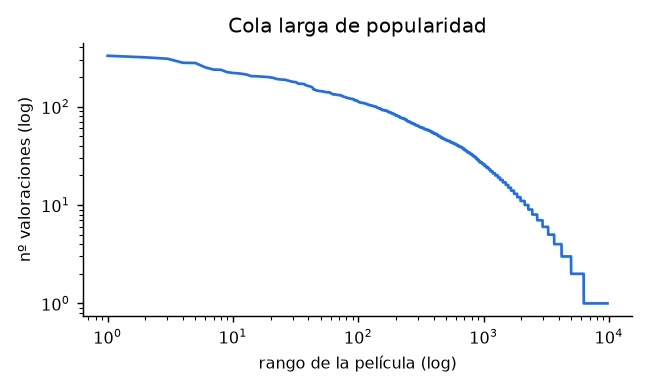

In [6]:
display(Image(FIG / 'long_tail.png'))

## 4. Particiones: corte temporal leave-last-out

In [7]:
display(res["split_info"])
print(res["summary"]["split"])

,particion,valoraciones,usuarios
0,entrenamiento,99616,610
1,validación (penúltima),610,610
2,prueba (última),610,610


{'sin_fuga_temporal_por_usuario': True, 'pct_items_prueba_no_vistos_en_train': 0.03770491803278689}


Para cada usuario, ordenado por *timestamp*: la **última** valoración va a **prueba**, la **penúltima** a **validación** y el resto a entrenamiento. Así el modelo nunca aprende del futuro de una persona para explicar su pasado. La prueba `test_temporal_split_has_no_future_leakage` lo verifica.
Límite: el corte es *por usuario*, no global. El entrenamiento puede contener valoraciones de **otras** personas posteriores al momento de prueba de alguien, y eso es una fuga leve entre usuarios. Además, el 3,8 % de los ítems de prueba no aparece en entrenamiento, así que ningún modelo colaborativo puede acertarlos.

## 5. Selección en validación y decisión Pareto

In [8]:
val = res["val"]
cols = ["modelo","factores","epocas","alpha","gamma","HitRate@10","HitRate@10_sd","NDCG@10","Cobertura","RMSE","costo_computo","seg_entrenamiento","pareto","dentro_1EE","cobertura_equivalente","elegida"]
print(f"mejor HitRate@10 validación = {val.attrs['best_hr']:.4f};  1 EE = {val.attrs['se']:.4f}")
display(val[val.pareto | (val.factores == 0)][cols].sort_values("HitRate@10", ascending=False))

mejor HitRate@10 validación = 0.0508;  1 EE = 0.0089


,modelo,factores,epocas,alpha,gamma,HitRate@10,HitRate@10_sd,NDCG@10,Cobertura,RMSE,costo_computo,seg_entrenamiento,pareto,dentro_1EE,cobertura_equivalente,elegida
15,Híbrido,10,12,0.50,0.50,0.0508,0.0016,0.0235,0.0165,0.8928,1.1954e+07,9.1691,True,True,False,False
74,Híbrido,50,12,0.25,0.50,0.0508,0.0000,0.0236,0.0260,0.8901,5.9770e+07,9.8204,True,True,False,False
29,Híbrido,10,25,0.25,0.50,0.0503,0.0009,0.0235,0.0272,0.8881,2.4904e+07,18.3353,True,True,False,False
14,Híbrido,10,12,0.25,0.50,0.0497,0.0009,0.0229,0.0257,0.8928,1.1954e+07,9.1691,True,True,False,False
59,Híbrido,20,25,0.25,0.50,0.0497,0.0025,0.0238,0.0274,0.8866,4.9808e+07,18.6776,True,True,False,False
26,Híbrido,10,25,0.75,0.25,0.0448,0.0041,0.0227,0.0325,0.8881,2.4904e+07,18.3353,True,True,False,False
13,Híbrido,10,12,0.00,0.50,0.0443,0.0000,0.0208,0.0349,0.8928,1.1954e+07,9.1691,True,True,False,False
56,Híbrido,20,25,0.75,0.25,0.0443,0.0033,0.0233,0.0378,0.8866,4.9808e+07,18.6776,True,True,True,False
86,Híbrido,50,25,0.75,0.25,0.0443,0.0057,0.0227,0.0414,0.8833,1.2452e+08,20.6325,True,True,True,False
10,Híbrido,10,12,0.50,0.25,0.0437,0.0009,0.0210,0.0377,0.8928,1.1954e+07,9.1691,True,True,True,True


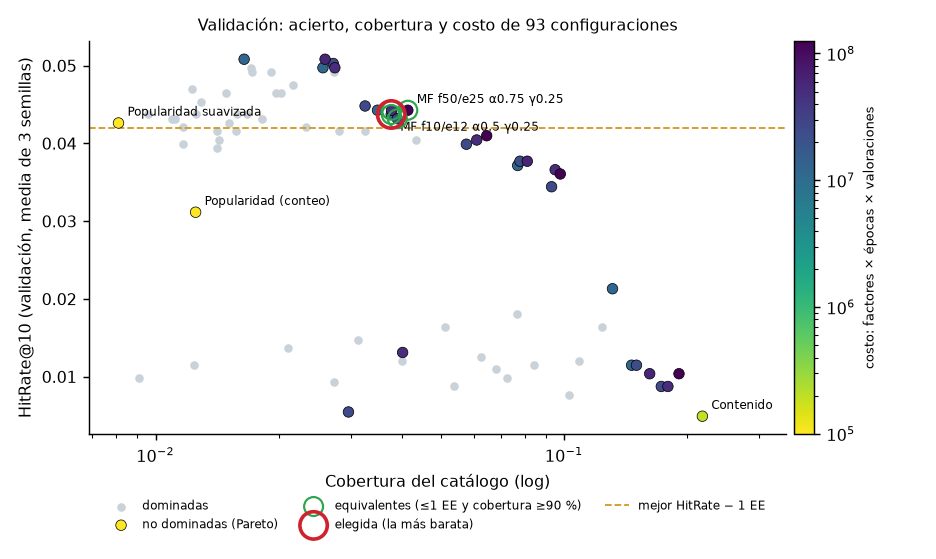

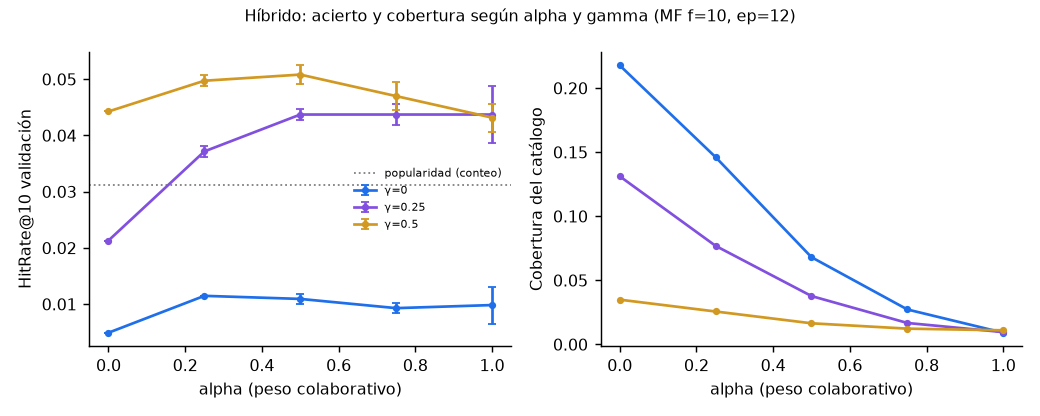

In [9]:
display(Image(FIG / 'pareto_validacion.png'))
display(Image(FIG / 'alpha_tradeoff.png'))

In [10]:
print(json.dumps(res["summary"]["decision"], indent=2, ensure_ascii=False))

{
  "modelo": "Híbrido",
  "factores": 10,
  "epocas": 12,
  "alpha": 0.5,
  "gamma": 0.25,
  "beta_frio": 0.5,
  "alpha_hibrido_lab09": 0.25,
  "val_HitRate@10": 0.04371584699453551,
  "mejor_val_HitRate": 0.05081967213114754,
  "1EE": 0.008892530762942885,
  "regla": "Pareto (HR@10, cobertura vs cómputo, parámetros) + 1 EE en HR + cobertura ≥ 90 % del máximo → la más barata",
  "popularidad_en_hibrido_y_fallback": "Popularidad (conteo)"
}


**Regla de decisión (protocolo v2, sólo validación):**
1. Se calcula la frontera de Pareto: maximizar HitRate@10 y cobertura, minimizar cómputo (factores × épocas × valoraciones) y parámetros. Una configuración está dominada si otra es igual o mejor en todo.
2. Se consideran equivalentes en acierto las que están a ≤ 1 error estándar binomial de la mejor HitRate@10. Con 610 usuarios, 1 EE ≈ 0,009: diferencias menores son ruido.
3. Entre ellas se consideran equivalentes en cobertura las que alcanzan ≥ 90 % de la mayor cobertura.
4. Se elige **la más barata** (Green AI): no se escoge automáticamente el modelo más grande.

**Qué muestra la figura de alpha:** sin prior de popularidad (γ = 0), al aumentar alpha la cobertura cae de 22 % a 1–4 % y el acierto se queda en ≈ 1 %. Domina la señal de contenido cuando alpha es bajo y la colaborativa cuando es alto, pero ninguna se acerca a la popularidad. Con γ > 0 el acierto sube al nivel de la popularidad y la cobertura se mantiene entre 3 y 4 veces mayor.

## 6. Resultado en prueba (evaluación única, 3 semillas)

In [11]:
t = res["test"]
main = ["modelo","RMSE","HitRate@10","HitRate@10_sd","HitRate@10_EE","NDCG@10","Precision@10","Cobertura","Cuota_cabeza","Novedad","Diversidad_ILD","Gini_exposicion","seg_entrenamiento","n_parametros"]
display(t[main])

,modelo,RMSE,HitRate@10,HitRate@10_sd,HitRate@10_EE,NDCG@10,Precision@10,Cobertura,Cuota_cabeza,Novedad,Diversidad_ILD,Gini_exposicion,seg_entrenamiento,n_parametros
0,Aleatorio,NaN,0.0011,0.0009,0.0011,0.0004,0.0001,0.4625,0.0866,7.4707,0.8040,0.6286,0.0000,0.0
1,Media global,1.1169,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0
2,Popularidad (conteo),NaN,0.0426,0.0000,0.0082,0.0194,0.0043,0.0125,1.0000,1.4201,0.7313,0.9976,0.0000,9742.0
3,Popularidad suavizada,1.0584,0.0344,0.0000,0.0074,0.0177,0.0034,0.0081,0.9997,1.7555,0.6894,0.9980,0.0000,9742.0
4,Sesgos usuario+ítem,0.9729,0.0230,0.0000,0.0061,0.0119,0.0023,0.0075,0.9987,2.1814,0.7523,0.9983,0.0000,0.0
5,Contenido (TF-IDF géneros),NaN,0.0082,0.0000,0.0037,0.0045,0.0008,0.2230,0.4752,5.1774,0.0796,0.8868,0.0000,185098.0
6,MF f=10 ep=12,0.9644,0.0109,0.0025,0.0042,0.0057,0.0011,0.0091,0.6205,3.9180,0.7441,0.9978,8.8415,113873.0
7,Híbrido LAB09 α=0.25 γ=0,NaN,0.0093,0.0009,0.0039,0.0054,0.0009,0.1441,0.4142,4.9265,0.1417,0.9431,8.8415,298971.0
8,Híbrido FINAL α=0.5 γ=0.25,NaN,0.0311,0.0028,0.0070,0.0156,0.0031,0.0378,0.9333,2.3049,0.4802,0.9903,8.8415,298971.0


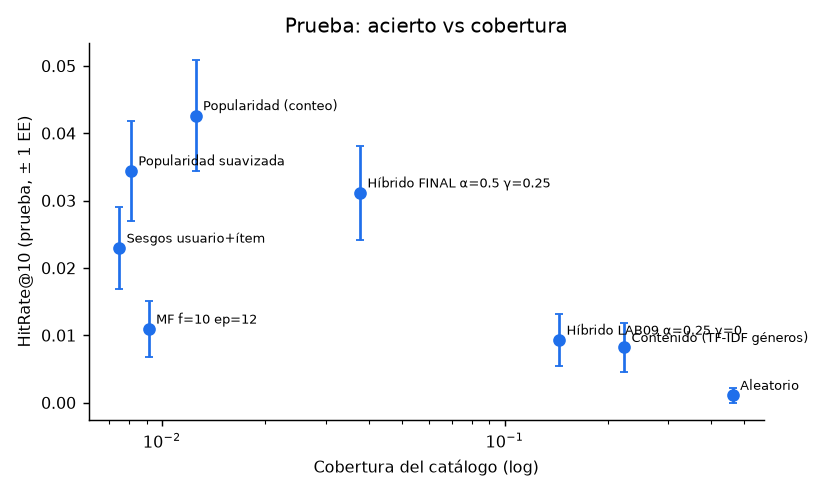

In [12]:
display(Image(FIG / 'test_hit_vs_coverage.png'))

Métricas: **HitRate@10** = proporción de usuarios cuya valoración retenida aparece en su Top-10 (sobre todo el catálogo no visto). Con un único ítem relevante, Precision@10 = HitRate@10 / 10. **NDCG@10** premia que aparezca más arriba. **Cobertura** = fracción del catálogo que aparece en alguna lista. **Cuota_cabeza** = fracción de posiciones ocupadas por el 10 % de películas más populares. **Gini_exposición** ∈ [0, 1] mide la concentración. `_sd` = desviación entre semillas; `_EE` = error estándar binomial entre usuarios.

### 6.1 ¿La diferencia con la popularidad es real? Comparación pareada

In [13]:
pr = res["pairs"]
display(pr)
display(pr.groupby("B")[["dif_HitRate","IC95_inf","IC95_sup","p_McNemar"]].mean())

,A,B,seed,dif_HitRate,IC95_inf,IC95_sup,aciertos_solo_A,aciertos_solo_B,p_McNemar,usuarios
0,Híbrido FINAL,Popularidad (conteo),42,-0.0082,-0.0262,0.0098,12,17,0.4583,610
1,Híbrido FINAL,MF sola,42,0.0213,0.0066,0.0361,17,4,0.0072,610
2,Híbrido FINAL,Híbrido LAB09 α=0.25 γ=0,42,0.0246,0.0115,0.0377,16,1,0.0003,610
3,Híbrido FINAL,Popularidad (conteo),7,-0.0131,-0.0311,0.0033,10,18,0.1849,610
4,Híbrido FINAL,MF sola,7,0.0180,0.0049,0.0311,14,3,0.0127,610
5,Híbrido FINAL,Híbrido LAB09 α=0.25 γ=0,7,0.0213,0.0098,0.0344,14,1,0.0010,610
6,Híbrido FINAL,Popularidad (conteo),2025,-0.0131,-0.0311,0.0033,10,18,0.1849,610
7,Híbrido FINAL,MF sola,2025,0.0213,0.0082,0.0344,15,2,0.0023,610
8,Híbrido FINAL,Híbrido LAB09 α=0.25 γ=0,2025,0.0197,0.0082,0.0311,13,1,0.0018,610


,dif_HitRate,IC95_inf,IC95_sup,p_McNemar
B,,,,
Híbrido LAB09 α=0.25 γ=0,0.0219,0.0098,0.0344,0.0010
MF sola,0.0202,0.0066,0.0339,0.0074
Popularidad (conteo),-0.0115,-0.0295,0.0055,0.2760


Se compara **usuario por usuario** (los mismos 610 usuarios de prueba): diferencia de HitRate@10, IC 95 % por bootstrap y prueba exacta de McNemar sobre los usuarios en los que sólo uno de los dos modelos acierta.

### 6.2 Ratings ≠ ranking

In [14]:
r = t.dropna(subset=["RMSE"])[["modelo","RMSE","HitRate@10"]].sort_values("RMSE")
display(r)

,modelo,RMSE,HitRate@10
6,MF f=10 ep=12,0.9644,0.0109
4,Sesgos usuario+ítem,0.9729,0.0230
3,Popularidad suavizada,1.0584,0.0344
1,Media global,1.1169,NaN


La factorización tiene el **mejor RMSE** (aproxima mejor las estrellas), pero su HitRate@10 está por debajo de la popularidad por conteo. Predecir *cuántas estrellas* daría alguien a una película no equivale a predecir *qué verá después*. Una película poco vista puede tener una predicción de 4,5 estrellas y casi ninguna probabilidad de ser la próxima que la persona valore.

### 6.3 Usuarios con historial pequeño vs amplio (modelo final)

In [15]:
display(res['buckets'])

,grupo,usuarios,min_hist,max_hist,HitRate@10
0,pequeño (tercil 1),209,19,44,0.0335
1,medio (tercil 2),198,45,126,0.0505
2,amplio (tercil 3),203,127,2697,0.0049


## 7. Usuarios fríos

In [16]:
print("Selección de beta (peso del contenido en el fallback) con usuarios fríos DISJUNTOS de los de prueba:")
display(res["beta"][["beta","HitRate@10","NDCG@10","Cobertura"]])
display(res["cold"][["escenario","modelo","HitRate@10","HitRate@10_sd","NDCG@10","Cobertura","usuarios_eval","fuente"]])

Selección de beta (peso del contenido en el fallback) con usuarios fríos DISJUNTOS de los de prueba:


,beta,HitRate@10,NDCG@10,Cobertura
0,0.00,0.1148,0.0545,0.0013
1,0.25,0.1311,0.0589,0.0030
2,0.50,0.1148,0.0463,0.0111
3,0.75,0.0492,0.0305,0.0326
4,1.00,0.0000,0.0000,0.0447


,escenario,modelo,HitRate@10,HitRate@10_sd,NDCG@10,Cobertura,usuarios_eval,fuente
0,0 valoraciones,Aleatorio,0.0000,0.0000,0.0000,0.0609,61.0,—
1,0 valoraciones,Popularidad (conteo),0.1421,0.0189,0.0635,0.0010,61.0,—
2,0 valoraciones,Popularidad suavizada,0.0984,0.0328,0.0439,0.0010,61.0,—
3,0 valoraciones,Híbrido FINAL → fallback,0.1421,0.0189,0.0635,0.0010,61.0,popularidad (NO personalizada)
4,3 valoraciones,Popularidad (conteo),0.1475,0.0164,0.0676,0.0013,61.0,—
5,3 valoraciones,Contenido,0.0109,0.0189,0.0055,0.0461,61.0,—
6,3 valoraciones,Híbrido FINAL → fallback,0.1093,0.0379,0.0556,0.0090,61.0,contenido+popularidad
7,cualquiera,MF sola,NaN,0.0000,NaN,NaN,61.0,sin vector para 61/61 usuarios


Simulación: el 10 % de los usuarios (61) se retira por completo del entrenamiento. Con **0 valoraciones** el híbrido no tiene vector colaborativo ni perfil de contenido, cae a **popularidad** y lo **declara** (`popularidad (NO personalizada)`). Con **3 valoraciones** de onboarding usa contenido + popularidad (beta elegido en una muestra fría disjunta). Se evalúa la valoración **siguiente** al onboarding.

## 8. Tres perfiles

In [17]:
p = res["profiles"]
for (perfil, a, g), q in p.groupby(["perfil","alpha","gamma"], sort=False):
    print(f"\n▶ {perfil} · usuario {q.userId.iloc[0]} · historial={q.n_historial.iloc[0]} · alpha={a:g} gamma={g:g} · fuente={q.fuente.iloc[0]} · personalizada={q.personalizada.iloc[0]}")
    display(q[["rank","title","genres"]].reset_index(drop=True))
print("¿Alguna recomendación ya vista?", p.visto_antes.any())


▶ Historial amplio · usuario 414 · historial=2697 · alpha=0.5 gamma=0.25 · fuente=híbrido · personalizada=True


,rank,title,genres
0,1,12 Angry Men (1957),Drama
1,2,Guess Who's Coming to Dinner (1967),Drama
2,3,"Seventh Seal, The (Sjunde inseglet, Det) (1957)",Drama
3,4,"Hustler, The (1961)",Drama
4,5,Secrets & Lies (1996),Drama
5,6,"Celebration, The (Festen) (1998)",Drama
6,7,All About My Mother (Todo sobre mi madre) (1999),Drama
7,8,All About Eve (1950),Drama
8,9,Three Colors: Red (Trois couleurs: Rouge) (1994),Drama
9,10,Mr. Smith Goes to Washington (1939),Drama



▶ Historial amplio · usuario 414 · historial=2697 · alpha=0.25 gamma=0 · fuente=híbrido · personalizada=True


,rank,title,genres
0,1,Guess Who's Coming to Dinner (1967),Drama
1,2,12 Angry Men (1957),Drama
2,3,"Seventh Seal, The (Sjunde inseglet, Det) (1957)",Drama
3,4,"Hustler, The (1961)",Drama
4,5,Secrets & Lies (1996),Drama
5,6,"Celebration, The (Festen) (1998)",Drama
6,7,Captain Fantastic (2016),Drama
7,8,Five Easy Pieces (1970),Drama
8,9,All About My Mother (Todo sobre mi madre) (1999),Drama
9,10,Three Colors: Red (Trois couleurs: Rouge) (1994),Drama



▶ Historial amplio · usuario 414 · historial=2697 · alpha=0.75 gamma=0 · fuente=híbrido · personalizada=True


,rank,title,genres
0,1,Guess Who's Coming to Dinner (1967),Drama
1,2,12 Angry Men (1957),Drama
2,3,"Seventh Seal, The (Sjunde inseglet, Det) (1957)",Drama
3,4,"Hustler, The (1961)",Drama
4,5,Secrets & Lies (1996),Drama
5,6,"Celebration, The (Festen) (1998)",Drama
6,7,Captain Fantastic (2016),Drama
7,8,Five Easy Pieces (1970),Drama
8,9,All About My Mother (Todo sobre mi madre) (1999),Drama
9,10,Three Colors: Red (Trois couleurs: Rouge) (1994),Drama



▶ Historial pequeño · usuario 53 · historial=19 · alpha=0.5 gamma=0.25 · fuente=híbrido · personalizada=True


,rank,title,genres
0,1,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
1,2,Forrest Gump (1994),Comedy|Drama|Romance|War
2,3,"Shawshank Redemption, The (1994)",Crime|Drama
3,4,Fight Club (1999),Action|Crime|Drama|Thriller
4,5,American Beauty (1999),Drama|Romance
5,6,Lost in Translation (2003),Comedy|Drama|Romance
6,7,Fargo (1996),Comedy|Crime|Drama|Thriller
7,8,"Philadelphia Story, The (1940)",Comedy|Drama|Romance
8,9,"Graduate, The (1967)",Comedy|Drama|Romance
9,10,"Matrix, The (1999)",Action|Sci-Fi|Thriller



▶ Usuario nuevo · usuario nuevo · historial=0 · alpha=0.5 gamma=0.25 · fuente=popularidad (NO personalizada) · personalizada=False


,rank,title,genres
0,1,Forrest Gump (1994),Comedy|Drama|Romance|War
1,2,"Shawshank Redemption, The (1994)",Crime|Drama
2,3,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
3,4,"Matrix, The (1999)",Action|Sci-Fi|Thriller
4,5,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
5,6,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,7,Braveheart (1995),Action|Drama|War
7,8,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
8,9,Terminator 2: Judgment Day (1991),Action|Sci-Fi
9,10,Fight Club (1999),Action|Crime|Drama|Thriller


¿Alguna recomendación ya vista? False


### 8.1 ¿Por qué alpha = 0,25 y alpha = 0,75 dan la misma lista al usuario de historial amplio?

In [18]:
from inf8239_u03.base import ItemIndex, histories, minmax
from inf8239_u03.content import ContentRecommender
from inf8239_u03.split import leave_last_out, merge_train_valid
idx = ItemIndex(ml.movies); tr = merge_train_valid(leave_last_out(ml.ratings))
uid = int(p[p.perfil == "Historial amplio"].userId.iloc[0])
h = histories(tr, idx)[uid]
cont = ContentRecommender().fit(None, idx, ml.movies)
cs = minmax(cont.score(uid, h))
print(f"usuario {uid}: {int((cs >= 0.999).sum())} películas ({(cs >= 0.999).mean():.1%} del catálogo) empatan en la similitud de contenido MÁXIMA")
print("géneros de esas películas:", pd.Series(idx.genres[cs >= 0.999]).value_counts().head(3).to_dict())

usuario 414: 1053 películas (10.8% del catálogo) empatan en la similitud de contenido MÁXIMA
géneros de esas películas: {'Drama': 1053}


El perfil de contenido de este usuario apunta a **Drama** y todas las películas etiquetadas sólo como *Drama* empatan en similitud = 1. El contenido funciona entonces como un **filtro de género** y la señal colaborativa ordena dentro de ese grupo. Cambiar alpha no altera el Top-10. Es una consecuencia directa de representar el contenido con sólo 20 géneros.

## 9. Reproducibilidad: determinismo con semilla

In [19]:
from inf8239_u03.matrix_factorization import MatrixFactorization
d = res["summary"]["decision"]
a = MatrixFactorization(d["factores"], d["epocas"], seed=42).fit(tr, idx)
b = MatrixFactorization(d["factores"], d["epocas"], seed=42).fit(tr, idx)
print("Mismos parámetros con la misma semilla:", np.array_equal(a.P, b.P) and np.array_equal(a.Q, b.Q))
print("Entorno:", res["summary"]["entorno"])

Mismos parámetros con la misma semilla: True
Entorno: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1'}


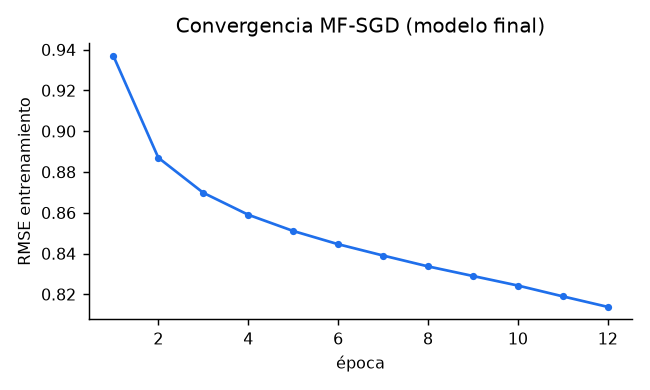

In [20]:
display(Image(FIG / 'mf_training_curve.png'))

## 10. Cierre interpretativo

| Pregunta | Respuesta con evidencia (prueba, media de 3 semillas) |
|---|---|
| **Resultado de ratings** | La MF (10 factores, 12 épocas) obtiene el mejor RMSE (0,964), apenas por debajo de los sesgos usuario+ítem (0,973), y bastante mejor que la popularidad suavizada (1,058) y la media global (1,117). |
| **Resultado de ranking** | La popularidad por conteo logra HitRate@10 = 0,043. El híbrido final llega a 0,031; la MF sola, a 0,011; el híbrido LAB09 sin prior, a 0,009; el contenido, a 0,008; el azar, a 0,001. **Mejor RMSE no implica mejor Top-10.** En la comparación pareada, la diferencia final vs popularidad no es significativa: el IC 95 % incluye el 0 en las 3 semillas. Final vs MF sola y final vs híbrido LAB09 sí favorecen al final. |
| **Cobertura del catálogo** | El híbrido final cubre el 3,8 % del catálogo frente al 1,25 % de la popularidad (×3). Su cuota de «cabeza» baja de 100 % a 93 % y su novedad sube de 1,42 a 2,30 bits. El contenido cubre el 22 %, pero casi no acierta. |
| **Usuario frío** | Con 0 valoraciones, la MF no tiene vector (61/61 usuarios) y el fallback de popularidad acierta en el 14 % de los casos, declarando que no es personalizado. Con 3 valoraciones, el fallback contenido+popularidad (beta = 0,5) logra 0,109, **por debajo** de la popularidad pura (0,148). El beta elegido con la muestra fría disjunta no se sostuvo en prueba (61 usuarios: mucha varianza). |
| **Configuración seleccionada y evidencia** | Híbrido con α = 0,5 y γ = 0,25, sobre MF de 10 factores y 12 épocas. En validación está a ≤ 1 EE de la mejor HitRate (0,044 vs 0,051), tiene cobertura equivalente (≥ 90 % del máximo) y es la más barata de ese grupo. La configuración de 50 factores y 25 épocas daba el mismo acierto con 10× más cómputo. |
| **Costo computacional** | ≈ 8–9 s de entrenamiento en CPU y ≈ 114 k parámetros de la MF + matriz TF-IDF de 185 k valores. La popularidad cuesta < 0,01 s y ocupa 9,7 k valores, y sigue en la frontera de Pareto. |
| **Riesgo principal y mitigación** | **Dominio de la popularidad y retroalimentación:** el 93 % de las posiciones son de la cabeza del catálogo y el Gini de exposición es 0,99. Si se despliega, las recomendaciones alimentarán los datos futuros y reforzarán la concentración. Mitigación: γ acotado (0,25), monitorizar cobertura y cuota de cabeza, reservar posiciones de exploración y re-evaluar periódicamente con corte temporal. |

**Decisión final.** Para usuarios con historial se adopta el **híbrido (α = 0,5, γ = 0,25)**. Su acierto es estadísticamente indistinguible del de la popularidad, aunque su estimación puntual en prueba es menor (−0,01). A cambio, triplica la cobertura y personaliza: los perfiles muestran listas distintas según el historial. Si el único objetivo fuera HitRate@10, la popularidad por conteo sería la elección y es una opción legítima en la frontera de Pareto. Para usuarios nuevos se usa popularidad por conteo, declarada como no personalizada. Con 3 valoraciones, la evidencia de prueba sugiere bajar beta o usar popularidad pura: es el siguiente experimento, a validar con más usuarios fríos.
